In [16]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
"""
Importing everything I will need

and defining the device that I want to use for training
"""

print(torch.version.cuda)  # Should not be None
print(torch.backends.cudnn.enabled)  # Should be True

# Get cpu or gpu device for training.
device = (
    "cuda" if torch.cuda.is_available()
     else "cpu"
)
print(f"Using {device} device")

11.8
True
Using cuda device


Problem 1: \
a: NLP Please discuss the recent trend of rapidly increasing sizes of NLP architectures.

In recent years, the size of NLP architectures has grown dramatically. This trend is driven by several key factors:

- scaling lows in deep learning: it has been shown that larger models perform better across a wider range of tasks, even tho the cost increase exponentially compared the same scale of gains obtained.
- When very big models have been created for the first time, some secondary skills emerged, like in-context learning, planning and multimodal understanding. This also lead to the belief that bigger models had to be the way to pursue.
- Hardware and software advancement: only recently we reached the point where the creation of such lagre models is viable, thanks to improvement in power and efficiency of GPUs and optimization in libraries that use those resources for deep learning algorithms.
- Competitive pressure: due to growing interest in the sector and consequent investments companies are racing against each other to perform the best over popular benchmarks, and the easiest way to improve model results over those is by just increasing the model size.

 b: Transfer Learning \
Classify the following example of transfer learning. More exactly, what are the domains and tasks, and which are being changed? \
Source: Using a step counter to monitor exercise in healthy people. \
Target: Using a step counter to indicate recovery progression in a patient

Source domain: X = natural numbers that represent the number of steps; P(X) = normal distribution of nuber of steps in healthy people \
Source tasks: y = level of fitness; F = predict the level of fitness (regression)

Target domain: X = natural numbers that represent the number of steps; P(X) = normal distribution of nuber of steps in patients during recovery  \
Target tasks: y = level of recovery; F = predict the level of recovery (regression)

c: Attention

Assume dotproduct attention, and that the hidden states of the encoder layer are [0,1,4],[-1,1,2],[1,1,1],[2,1,1]. If the activation for the previous decoder is [0.1,1,-2], what is the attention-context vector?


In [17]:
encoder_layers = np.array([
    [0, 1, 4],
    [-1, 1, 2],
    [1, 1, 1],
    [2, 1, 1]
])
decoder_activation = np.array([0.1, 1, -2])

# Compute dot products between decoder activation and each encoder state
scores = encoder_layers @ decoder_activation

# Apply softmax to scores to get attention weights
def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / e_x.sum()

attention_weights = softmax(scores)

# Compute context vector as weighted sum of encoder states
context_vector = np.sum(encoder_layers * attention_weights[:, np.newaxis], axis=0)

print("Encoder states:\n", encoder_layers)
print("\nDecoder activation:", decoder_activation)
print("\nDot-product scores:", scores)
print("\nAttention weights:", attention_weights)
print("\n So the attention context-vector is:", context_vector)

Encoder states:
 [[ 0  1  4]
 [-1  1  2]
 [ 1  1  1]
 [ 2  1  1]]

Decoder activation: [ 0.1  1.  -2. ]

Dot-product scores: [-7.  -3.1 -0.9 -0.8]

Attention weights: [0.00101111 0.04995145 0.45081253 0.4982249 ]

 So the attention context-vector is: [1.39731088 1.         1.05298479]


d: Transformers

Explain the 'positional encoding' step for transformers. Why is it done, how is it done?

Due to how they are built transformer by them self loose completely the information about the order of the tokens, therefore, since that is valuable information somthing has to be done to preserve it. Specifically in the 'positional encoding' step we sum the original token embeddings with the value of sin and cosine waves so that each token can have slightly different representation based on its original position in the input. This gives the model a way to differentiate the tokens based on the position, and helps the performance of the model. 

e: Bounding box detection:\
Given a dataset with two classes; cats and dogs, and the following detections:

TP = True positive
FP = False positive

cat_det = [TP, FP, TP, FP, TP]
pred_scores_cat = [0.7, 0.3, 0.5, 0.6, 0.5]

dog_det = [FP, TP, TP, FP, TP, TP]
pred_scores_dog = [0.4, 0.3, 0.9, 0.5, 0.6, 0.7]


There are in total 3 cats and 4 dogs in the images.

Calculate the mean average precision (mAP)

I order the detections by pred_scores, so:

cat_det = [TP, FP, TP, TP, FP]

dog_det = [TP, TP, TP, FP, FP, TP]

I calculate TP_cumul and FP_cumul:

Cats:
TP_cumul = [1, 1, 2, 3, 3]\
FP_cumul = [0, 1, 1, 1, 2]

Dogs:
TP_cumul = [1, 2, 3, 3, 3, 4]\
FP_cumul = [0, 0, 0, 1, 2, 2]

I calculate precision and recall values:

Cats:
precision = [1, 1/2, 2/3, 3/4, 3/5]\
precision = [1/3, 1/3, 2/3, 1, 1]

so the average precision is AP_cat = 5/6 ≈ 0.83

Dogs:
precision = [1, 1, 1, 3/4, 3/5, 4/6]\
recall = [1/4, 1/2, 3/4, 3/4, 3/4, 1]

so the average precision is AP_dog = 11/12 ≈ 0.91

mAP = (AP_dog + AP_cat)/2 = (5/6 + 11/12) / 2 = 21/24 = 0.875

 f: Semantic segmentation - FCN 1:

Given an image sized 1024x768x3 (width x height x channels), with 7 classes. What is the size of the target image if targets are one-hot encoded?

1024x768x7  (width x height x channels) and each pixel is 1 in only one of the 7 channels (the one that represent the class it's assigned to)

g: Semantic segmentation - FCN 2: \
What is a fully-convolutional network? When is it useful?

A fully-convolutional network is a network that outputs a feature map and does that by using convolutions and "deconvolution" layers also called transposed convolution and does not contain fully-connected layers at all. It can be useful for semantic segmentation, where we want to assign each pixel of an image to a class, this is because it preserves spatial information throughout all the network.

h:Residual Networks:\
Explain residual layers and their advantage.

A residual connection is a connection between non-neighbour layers. Therefore a residual network is a network that contains at least a residual connection. This is useful to because gives the possibility to the layers that are skipped by this connection to only try to extrapolate some usefull information from the input without having to also preserve the information available before, since those information will be forwarded trough the residual connection.

i: Intersection-Over-Union\
Calculate the intersection over union in for these four bounding-boxes and target bounding boxes:

A: 4/14   \
B: 9/25   \
C: 6/13   \
D: 6/12

j: Variational autoencoders:\
What are the strengths of a variational autoencoder (VAE) compared to an autoencoder (AE)?

By making the model learn a probabilistic distribution instead of a deterministic mapping between input and outputs, VAEs lear a smooth latent space, that can be used to generate new data in a controlled and effective way, because small changes in the latent space lead to gradual changes in the output.

Problem 2:
In this problem, you will build a waveform detector for 1D time series. Below is shared a piece of code defining a (train) dataset and a test set. As you will see when you open the file, the data is synthetic - a waveform is combined with a background 'noise' signal, allowing virtually infinite training data.

The task is:

Using the dataset supplied below, create a neural network which can detect the ends of waveforms (marked by '1' in the labels).

You are free to use either GRU, LSTM, xLSTM, state space models or Transformers to do the task.

Dataset generation: data_setup

use the 'waveformLoader' as data loader for your training data, and 'testX,testy' as the test data. Report your performance as an average loss over the test data and with a plot of 'testy' and 'net(testX)' as a function of time, such as:

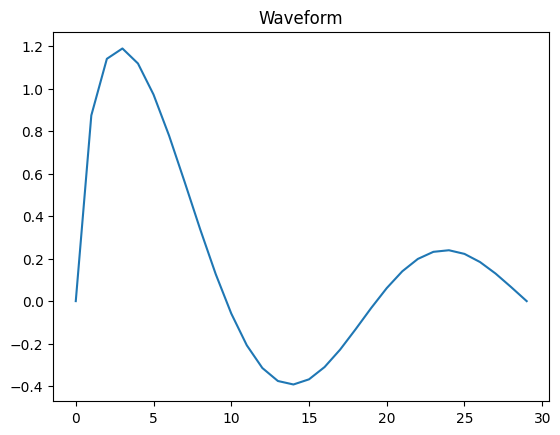

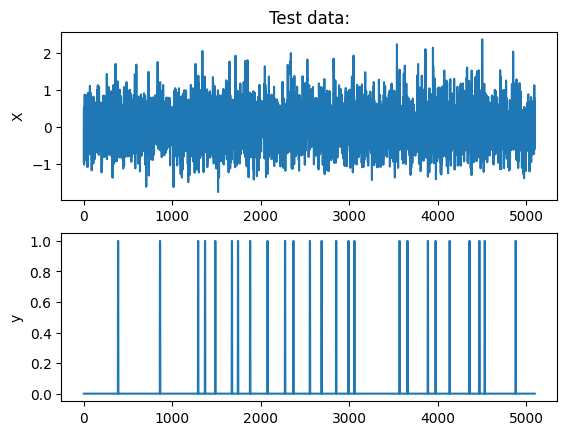

In [18]:
#Prepare waveform data set container:
class waveFormDataset(torch.utils.data.Dataset):
    """waveFormDetectionDataset"""

    def __init__(self, waveforms, backgroundGenerator, targetRate=1):
        """
        Args:
            waveforms: array of size nxl, showing n different examples of target waveforms, length l
            backgroundGenerator: function, no input, outputs non-target signals, length L>l
        """

        if len(waveforms.shape) == 0:
            waveforms = np.expand_dims(waveforms, 0)

        self.ntargets = waveforms.shape[0]
        self.targets = waveforms
        self.backgroundGenerator = backgroundGenerator
        self.targetRate = targetRate

    def __len__(self):
        return 100000  #arbitrary

    def __getitem__(self, idx):
        #combines targets and backgroundGenerator. includes target in targetRate*100 percentage of outputs

        sample = self.backgroundGenerator()

        assert (len(sample) >= self.targets.shape[1])

        labels = sample * 0

        if np.random.rand() <= self.targetRate:
            target = self.targets[np.random.randint(0, self.ntargets), :]
            target = torch.reshape(target, (-1, 1))
            targetL = len(target)

            backgroundL = len(sample)

            endBuffer = 4  #we need to ensure a bit of space at the end for placing 1-labels
            startIdx = np.random.randint(0, backgroundL - targetL - endBuffer, 1)[0]
            sample[startIdx:(startIdx + targetL)] = sample[startIdx:(startIdx + targetL)] + target
            labels[startIdx + targetL + range(0, endBuffer)] = 1

        return sample, labels
# %%
# setup dataset

#training:
targetL = 30
waveform = np.sin(np.linspace(0, np.pi * 3, targetL)) / np.linspace(.2, 5, targetL)
waveform = np.expand_dims(waveform, 0)
waveform = torch.tensor(waveform, dtype=torch.float32)


def bgg():
    backgroundL = 100
    scale = .5
    background = torch.tensor(np.random.normal(0, scale=scale, size=(backgroundL, 1)), dtype=torch.float32)
    return background


wfDataset = waveFormDataset(waveform, bgg, .5)
e = wfDataset.__getitem__(1)
waveformLoader = torch.utils.data.DataLoader(wfDataset, batch_size=32)
# %%

#seed random number generator:
torch.manual_seed(1066)
np.random.seed(1066)

#test dataset:
nTest = 50
testX, testy = wfDataset.__getitem__(1)

for iVal in range(nTest):
    x, y = wfDataset.__getitem__(1)
    testX = torch.cat((testX, x), 0)
    testy = torch.cat((testy, y), 0)

testX = torch.unsqueeze(testX, 0)

plt.plot(waveform[0, :])
plt.title('Waveform')
plt.figure()
plt.subplot(2, 1, 1)
plt.plot(testX[0, :])
plt.ylabel('X')
plt.title('Test data:')

plt.subplot(2, 1, 2)
plt.plot(testy[:, 0])
plt.ylabel('y');

In [19]:
def class_wise_accuracies_mean(predictions, target,tolerance):
    correct_0 = 0
    len_0 = 0
    correct_1 = 0
    len_1 = 0
    for p,t in zip(predictions, target):
        if t == 0:
            len_0 += 1
            if abs(p-t) <= tolerance:
                correct_0 += 1
        else:
            len_1 += 1
            if abs(p-t) <= tolerance:
                correct_1 += 1
    accuracy_0 = correct_0 / len_0 if len_0!=0 else 1
    accuracy_1 = correct_1 / len_1 if len_1!=0 else 1
    return (accuracy_0 + accuracy_1) / 2

def f1score(predictions, targets, tolerance=0.5):
    # Convert probabilities or continuous predictions to binary (0 or 1)
    preds_bin = [1 if p >= tolerance else 0 for p in predictions]

    tp = sum(p == 1 and t == 1 for p, t in zip(preds_bin, targets))
    fp = sum(p == 1 and t == 0 for p, t in zip(preds_bin, targets))
    fn = sum(p == 0 and t == 1 for p, t in zip(preds_bin, targets))

    if tp + fp == 0 or tp + fn == 0:
        return 0.0

    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    return 2 * precision * recall / (precision + recall)

class GRUWaveformDetector(nn.Module):
    def __init__(self):
        super(GRUWaveformDetector, self).__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 1)  # Output one value per time step

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out)
        return out


In [20]:
num_samples = len(wfDataset)

num_positives = 0
num_negatives = 0
for i, (x, y) in enumerate(waveformLoader):
    num_positives += (y == 1).sum().item()
    num_negatives += (y == 0).sum().item()

pos_weight = torch.tensor([num_negatives / num_positives], device=device)
print(f"class imbalance: {pos_weight}")

model = GRUWaveformDetector()
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

n_epochs = 100

for epoch in range(n_epochs):
    model.to(device)
    model.train()
    tot_loss = 0
    for batch_x, batch_y in waveformLoader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        tot_loss += loss.item()
        optimizer.step()

    if (epoch+1) % 10 == 0:
        outputs_cpu = outputs.to('cpu')
        preds = torch.sigmoid(outputs_cpu).squeeze().detach().numpy().squeeze()
        targets = batch_y.to('cpu').detach().numpy().squeeze()
        tot_f1score = 0
        tot_class_wise_accuracies_mean = 0
        for pred, target in zip(preds,targets):
            tot_f1score += f1score(pred, target)
            tot_class_wise_accuracies_mean += class_wise_accuracies_mean(pred, target,0.4)
        print(f"Epoch {epoch+1}/{n_epochs},class_wise_accuracies_mean: {tot_class_wise_accuracies_mean/len(preds):.4f}, Loss: {tot_loss/len(waveformLoader):.4f}")


class imbalance: tensor([48.9301], device='cuda:0')
Epoch 10/100,class_wise_accuracies_mean: 0.9909, Loss: 0.0602
Epoch 20/100,class_wise_accuracies_mean: 0.9926, Loss: 0.0549
Epoch 30/100,class_wise_accuracies_mean: 0.9915, Loss: 0.0540
Epoch 40/100,class_wise_accuracies_mean: 0.9931, Loss: 0.0522
Epoch 50/100,class_wise_accuracies_mean: 0.9740, Loss: 0.0517
Epoch 60/100,class_wise_accuracies_mean: 0.9920, Loss: 0.0518
Epoch 70/100,class_wise_accuracies_mean: 0.9939, Loss: 0.0506
Epoch 80/100,class_wise_accuracies_mean: 0.9932, Loss: 0.0508
Epoch 90/100,class_wise_accuracies_mean: 0.9950, Loss: 0.0521
Epoch 100/100,class_wise_accuracies_mean: 0.9890, Loss: 0.0506


In [21]:
model.eval()
with torch.no_grad():
    preds = model(testX.to(device))
    preds = torch.sigmoid(preds).squeeze().to('cpu').numpy()

print(f"F1score: ",f1score(preds, testy))
print(f"class_wise_accuracies_mean: ",class_wise_accuracies_mean(preds, testy,0.4))

F1score:  tensor([0.7711])
class_wise_accuracies_mean:  0.9689


I decided to go for a simple GRU with a single hidden layer with 64 nodes, then I trained it using BCEWithLogitsLoss that combines a layer of sigmoid and the BCELoss and with the Adam optimizer, specifically with learning_rate=0.0005 and pos_weight=48.93 that is the proportion between the 2 classes in this specific case, this is to punish more the miss-classified data of the minoritarian class. Then I increased the lenght of the dataset to 100000 and I trained over 100 epochs printing the progress every 10.

With this I reached a class-wise accuracy mean on the training batches on average around 0.99 towards the end of the training.
And an F1score of 0.7711 over the test set.\

Before coming to this result I also tried LSTM and in both cases I changed some of the hyperparameters based on the training set results, that in this case is the same as using a separate evaluation set since each training instance is different due to the data being always new.

Finally, we can visualize the result:

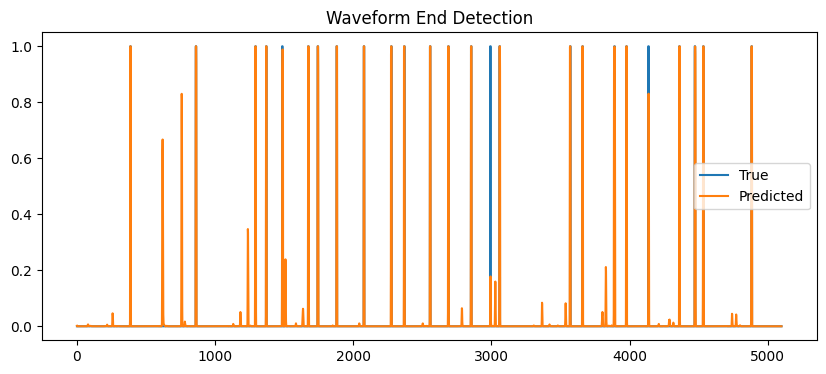

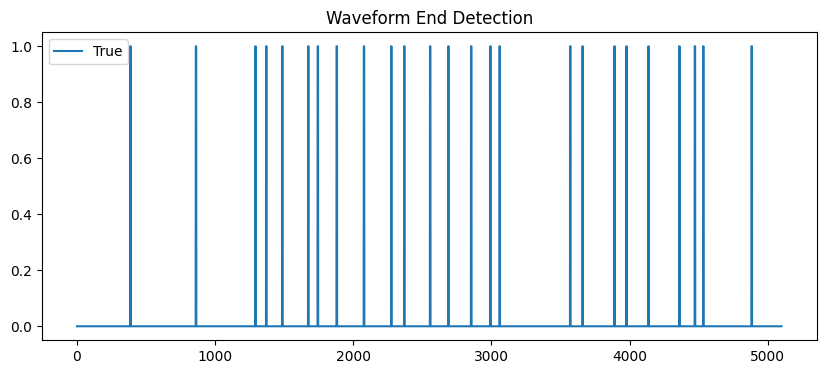

In [22]:
plt.figure(figsize=(10, 4))
plt.plot(testy.numpy(), label='True')
plt.plot(preds, label='Predicted')
plt.legend()
plt.title('Waveform End Detection')
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(testy.numpy(), label='True')
plt.legend()
plt.title('Waveform End Detection')
plt.show()
